# ¿Qué recuerda una red cuando escribe?
**ML2 · Universidad Panamericana | Laboratorio de PyTorch**

Escribe `Shall I ` en el pizarrón. ¿Qué letra pondrías después? Ahora escribe `def `. El espacio final es idéntico. La historia anterior cambia qué continuación tiene sentido. **¿Cuándo vale la pena pagar por la memoria adicional de una LSTM?**

Al terminar podrás **construir** los pares entrada–objetivo de un modelo de caracteres, **explicar** qué estado pasa de un paso al siguiente y **elegir** entre RNN y LSTM usando validación, costo y ejemplos del mismo corpus.

| Recorrido sugerido | Qué harás |
|---|---|
| 15 min · Datos | Desplazar una palabra a mano y revisar los caracteres del corpus. |
| 25 min · Modelos | Seguir un tensor por las dos redes y predecir qué cambia. |
| 25 min · Sonetos | Entrenar el par, leer sus curvas y medir hasta dónde llega el gradiente. |
| 25 min · Python | Entrenar un segundo par y completar una función realista. |
| 10 min · Chat y cierre | Probar tus propios prefijos y defender una elección. |

**Para empezar.** En Colab, ejecuta todo una vez. Una GPU es opcional. La primera ejecución descarga los sonetos. Para repetir una consulta, vuelve directamente a la sección 7. Los resultados guardados corresponden a una ejecución de referencia.

## 1. ¿Qué ve el modelo cuando lee «casa»?

Cubre la fila de objetivos. Si el modelo ya leyó `ca`, ¿en qué columna se evalúa su predicción y qué carácter debe acertar? La predicción de cada columna puede usar todo el prefijo que la precede, incluido el carácter de entrada de esa columna.

In [1]:
palabra = "casa"
print("Paso      ", *range(1, len(palabra)))
print("Entrada   ", *palabra[:-1])
print("Objetivo  ", *palabra[1:])

Paso       1 2 3
Entrada    c a s
Objetivo   a s a


En la segunda columna la entrada es `a`, el prefijo acumulado es `ca` y el objetivo es `s`. Una palabra de cuatro caracteres da tres predicciones supervisadas. Durante el entrenamiento entregamos el carácter real en cada paso. Al generar, el carácter elegido por el modelo se convierte en su siguiente entrada.

In [2]:
import ast
import hashlib
import math
import sys
import sysconfig
import time
from html import escape
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from IPython.display import HTML, display

SEMILLA = 42
EPOCAS, B, T = 8, 16, 48
EMBEDDING, OCULTAS = 32, 96
DISP = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DISP.type == "cpu":
    torch.set_num_threads(min(2, torch.get_num_threads()))
print(f"PyTorch {torch.__version__} · Python {sys.version.split()[0]} · {DISP}")

PyTorch 2.6.0+cpu · Python 3.12.14 · cpu


### Los dos bancos de prueba
Apartamos poemas completos para validación antes de construir el vocabulario. En Python reservamos módulos distintos. Así podremos preguntar qué aprende el modelo acerca de un poema o un archivo que nunca vio. Conservamos espacios, saltos de línea y signos de puntuación.

In [3]:
ruta = Path("sonnets_ml2.txt")
url = "https://raw.githubusercontent.com/ccc-frankfurt/Practical_ML_SS21/master/week06/sonnets.txt"
huella = "4c3b3ef3d45c051b0a0ae93da4cf0cd655b5b2527b5e8b6d1e0fedd376cd5bec"
if not ruta.exists():
    with urlopen(url, timeout=30) as respuesta:
        contenido = respuesta.read()
    if hashlib.sha256(contenido).hexdigest() != huella:
        raise ValueError("La descarga difiere de la edición usada en clase.")
    ruta.write_bytes(contenido)
assert hashlib.sha256(ruta.read_bytes()).hexdigest() == huella
poemas = ruta.read_text(encoding="utf-8").strip().split("\n\n")

# Cada partición es un flujo literario continuo con el separador original.
sonetos = (["\n\n".join(poemas[:-16])], ["\n\n".join(poemas[-16:])])
print(f"{len(poemas) - 16} sonetos de entrenamiento · 16 de validación")
print(poemas[0].splitlines()[0])

138 sonetos de entrenamiento · 16 de validación
From fairest creatures we desire increase,


In [4]:
stdlib = Path(sysconfig.get_path("stdlib"))
def leer_modulos(nombres, limite):
    # Una entrada por archivo. El límite mantiene breve la práctica en CPU.
    return [(stdlib / f"{nombre}.py").read_text(encoding="utf-8")[:limite]
            for nombre in nombres]

codigo = (leer_modulos(["functools", "dataclasses", "enum", "textwrap"], 24000),
          leer_modulos(["inspect", "argparse"], 12000))
print(f"CPython {sys.version.split()[0]} · los archivos pueden variar entre versiones")
print("Caracteres por archivo (entrenamiento):", [len(doc) for doc in codigo[0]])
print("Caracteres por archivo (validación):", [len(doc) for doc in codigo[1]])

CPython 3.12.14 · los archivos pueden variar entre versiones
Caracteres por archivo (entrenamiento): [24000, 24000, 24000, 19718]
Caracteres por archivo (validación): [12000, 12000]


### Del carácter al índice

Cada corpus tiene su propia tabla. Reservamos el índice 0 para caracteres ausentes en entrenamiento. En validación cuentan como una clase desconocida. En el chat señalaremos un prefijo desconocido para que el alumno pueda editarlo.

In [5]:
def preparar(particiones):
    train, val = particiones
    simbolos = ["<desc>"] + sorted(set("".join(train)))
    indice = {s: i for i, s in enumerate(simbolos)}
    def codificar(documentos):
        return [torch.tensor([indice.get(ch, 0) for ch in doc], dtype=torch.long)
                for doc in documentos]
    return dict(simbolos=simbolos, indice=indice, train=codificar(train), val=codificar(val))

datos = {"Sonetos": preparar(sonetos), "Python": preparar(codigo)}
for corpus, d in datos.items():
    print(f"{corpus}: {len(d['simbolos'])} clases; "
          f"{sum(int((doc == 0).sum()) for doc in d['val'])} caracteres desconocidos en validación")
print("Shall →", [datos["Sonetos"]["indice"][ch] for ch in "Shall"])

Sonetos: 62 clases; 0 caracteres desconocidos en validación
Python: 98 clases; 0 caracteres desconocidos en validación
Shall → [30, 43, 36, 47, 47]


### Ventanas que sí se pueden encadenar
Dos alumnos leen simultáneamente dos renglones de `abcdefghijklmnop`, uno desde `a` y otro desde `i`. Una ventana de tres letras da `abc → bcd` y `ijk → jkl`. Predice la **entrada** del segundo lote antes de ejecutar la celda.

Cada fila continúa por su propio carril. El último objetivo procede del mismo carril. Recortamos como máximo $B-1$ caracteres al formar el rectángulo y conservamos la última ventana corta. Al empezar otro archivo reiniciamos la memoria.

In [6]:
def ventanas(doc, filas, longitud):
    ancho = len(doc) // filas
    if ancho < 2:
        raise ValueError("Se necesitan al menos dos caracteres por carril.")
    carriles = doc[:filas * ancho].reshape(filas, ancho)
    for inicio in range(0, ancho - 1, longitud):
        fin = min(inicio + longitud, ancho - 1)
        yield carriles[:, inicio:fin], carriles[:, inicio + 1:fin + 1]

abc = "abcdefghijklmnop"
for paso, (x, y) in enumerate(ventanas(torch.arange(len(abc)), 2, 3), 1):
    pares = [("".join(abc[i] for i in a), "".join(abc[i] for i in b)) for a, b in zip(x, y)]
    print(f"Lote {paso} · entrada → objetivo: {pares}")

Lote 1 · entrada → objetivo: [('abc', 'bcd'), ('ijk', 'jkl')]
Lote 2 · entrada → objetivo: [('def', 'efg'), ('lmn', 'mno')]
Lote 3 · entrada → objetivo: [('g', 'h'), ('o', 'p')]


## 2. Cambia una pieza de la red
La **RNN** condensa lo leído en $h_t=\tanh(W_x e_t+W_h h_{t-1}+b)$. Para conservar una pista lejana, sus actualizaciones sucesivas deben preservarla.

La **LSTM** guarda además una celda $c_t=f_t\odot c_{t-1}+i_t\odot g_t$ y expone $h_t=o_t\odot\tanh(c_t)$. Si una coordenada tiene $c_{t-1}=0.8$, $f_t=1$ e $i_t=0$, seguirá valiendo **0.8**. Si $f_t=0$, $i_t=1$ y la propuesta $g_t=-0.3$, pasará a **−0.3**. Los datos de entrenamiento determinan cuándo sus compuertas se aproximan a estos extremos.

| Etapa | Forma con un lote de dos secuencias de tres caracteres | Significado |
|---|---|---|
| Índices | $2\times3$ | Un entero por posición |
| Embedding | $2\times3\times E$ | Vector aprendido para cada carácter |
| Salida recurrente | $2\times3\times H$ | Un estado visible por posición |
| Proyección lineal | $2\times3\times V$ | Un puntaje por posible carácter |
| Estado para el siguiente lote | $1\times2\times H$ por tensor | RNN entrega $h$ y LSTM entrega $(h,c)$ |

Fijamos una capa y el mismo ancho oculto. La LSTM calcula cuatro transformaciones internas. Comparamos la calidad y el costo a igual número de actualizaciones y mostramos los parámetros de cada red.

In [7]:
class ModeloCaracteres(nn.Module):
    def __init__(self, arquitectura, vocabulario):
        super().__init__()
        self.embedding = nn.Embedding(vocabulario, EMBEDDING)
        modulo = {"RNN": nn.RNN, "LSTM": nn.LSTM}[arquitectura]
        self.recurrente = modulo(EMBEDDING, OCULTAS, batch_first=True)
        self.salida = nn.Linear(OCULTAS, vocabulario)

    def forward(self, indices, estado=None):
        vectores = self.embedding(indices)
        secuencia, estado = self.recurrente(vectores, estado)
        return self.salida(secuencia), estado

x = datos["Sonetos"]["train"][0][:6].reshape(2, 3)
for arq in ("RNN", "LSTM"):
    red = ModeloCaracteres(arq, len(datos["Sonetos"]["simbolos"]))
    logits, estado = red(x)
    estados = estado if isinstance(estado, tuple) else (estado,)
    print(arq, "· logits", tuple(logits.shape), "· estado", [tuple(e.shape) for e in estados])

RNN · logits (2, 3, 62) · estado [(1, 2, 96)]
LSTM · logits (2, 3, 62) · estado [(1, 2, 96), (1, 2, 96)]


## 3. ¿Qué significa «mejor» en este experimento?
Si la letra verdadera es `s`, darle probabilidad 0.5 cuesta $-\ln(0.5)=0.69$ y darle 0.05 cuesta $3.00$. Promediamos ese costo sobre **todos los caracteres objetivo** de validación. Menor entropía cruzada (CE) es mejor. La perplejidad $e^{\mathrm{CE}}$ expresa el mismo resultado en otra escala.

Como referencia, un **unigrama** siempre predice según las frecuencias de entrenamiento. Si la red lo supera, usar el prefijo le está aportando información. Compara puntuaciones **dentro de cada corpus**.

Al entrenar, el estado numérico pasa a la ventana siguiente. `detach()` corta el grafo en ese límite y evita retropropagar a través de todas las ventanas anteriores. Durante validación recorremos cada archivo en un solo carril desde el principio y ponderamos las pérdidas por el número de caracteres.

In [8]:
def separar(estado):
    if isinstance(estado, tuple):
        return tuple(t.detach() for t in estado)
    return estado.detach()

def epoca(red, documentos, optimizador=None):
    entrenando = optimizador is not None
    red.train(entrenando)
    filas, longitud = (B, T) if entrenando else (1, 256)
    total = torch.zeros((), device=DISP)
    cantidad = 0
    with torch.set_grad_enabled(entrenando):
        for documento in documentos:
            estado = None
            for x, y in ventanas(documento, filas, longitud):
                x, y = x.to(DISP), y.to(DISP)
                logits, estado = red(x, estado)
                perdida = nn.functional.cross_entropy(logits.flatten(0, 1), y.reshape(-1))
                if entrenando:
                    optimizador.zero_grad(set_to_none=True)
                    perdida.backward()
                    nn.utils.clip_grad_norm_(red.parameters(), 1.0)
                    optimizador.step()
                estado = separar(estado)
                total += perdida.detach() * y.numel()
                cantidad += y.numel()
    return total.item() / cantidad

def ce_unigrama(d):
    conteos = torch.bincount(torch.cat(d["train"]), minlength=len(d["simbolos"]))
    probabilidades = (conteos + 1) / (conteos.sum() + len(conteos))
    objetivos = torch.cat([doc[1:] for doc in d["val"]])
    return -probabilidades[objetivos].log().mean().item()

In [9]:
modelos, historial = {}, {}
def entrenar_par(corpus):
    d = datos[corpus]
    filas = []
    for arq in ("RNN", "LSTM"):
        torch.manual_seed(SEMILLA)
        red = ModeloCaracteres(arq, len(d["simbolos"])).to(DISP)
        opt = torch.optim.Adam(red.parameters(), lr=0.003)
        inicio = time.perf_counter()
        for n in range(1, EPOCAS + 1):
            train = epoca(red, d["train"], opt)
            val = epoca(red, d["val"])
            filas.append(dict(modelo=arq, época=n, CE_train=train, CE_val=val,
                              PPL_val=math.exp(val), parámetros=sum(p.numel() for p in red.parameters()),
                              segundos=time.perf_counter() - inicio))
        modelos[corpus, arq] = red.eval()
        print(f"{corpus} · {arq} entrenada · CE final {val:.3f}")
    historial[corpus] = pd.DataFrame(filas)

def comparar(corpus):
    df = historial[corpus]
    base = ce_unigrama(datos[corpus])
    ax = None
    for (arq, color) in [("RNN", "#007681"), ("LSTM", "#9b4524")]:
        grupo = df[df.modelo == arq]
        ax = grupo.plot(x="época", y="CE_val", ax=ax, color=color, label=f"{arq} validación", marker="o")
        grupo.plot(x="época", y="CE_train", ax=ax, color=color, label=f"{arq} entrenamiento", linestyle=":")
    ax.axhline(base, color="#555", linestyle="--", label="Unigrama en validación")
    ax.set(xlabel="Época", ylabel="Entropía cruzada (nats/carácter)", title=corpus)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    final = df[df["época"] == EPOCAS].set_index("modelo")
    display(final[["CE_val", "PPL_val", "parámetros", "segundos"]].round(3))
    print(f"Unigrama · CE {base:.3f} · PPL {math.exp(base):.2f}")

## 4. Sonetos · mismo prefijo, dos escritores
Cada modelo recibe los mismos poemas, las mismas ventanas, el mismo optimizador y las mismas épocas. Usaremos el estado de la **última época** en el chat. Antes de mirar la gráfica, apuesta por un modelo. ¿Qué resultado te haría cambiar de opinión?

Sonetos · RNN entrenada · CE final 1.815
Sonetos · LSTM entrenada · CE final 1.808
Unigrama · CE 3.114 · PPL 22.51


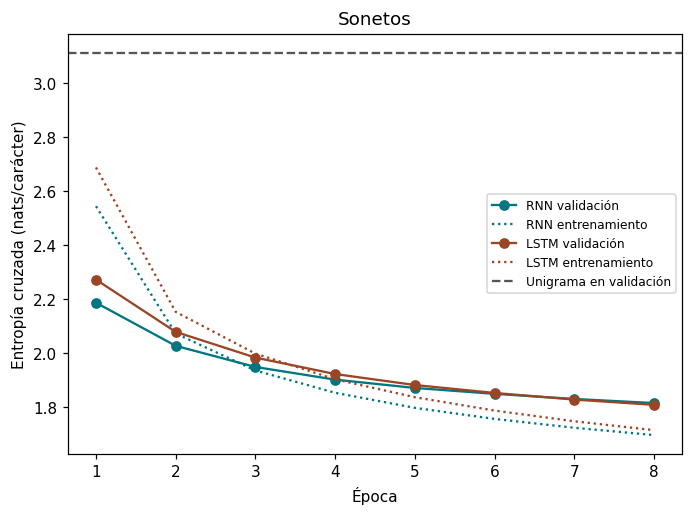

,CE_val,PPL_val,parámetros,segundos
modelo,,,,
RNN,1.815,6.141,20478,4.006
LSTM,1.808,6.100,57918,3.889


In [10]:
entrenar_par("Sonetos")
comparar("Sonetos")

### Observa la decisión antes de leer el poema
Al terminar de leer el prefijo obtenemos una distribución para la primera letra nueva. Después muestreamos y realimentamos esa letra. La temperatura redistribuye la probabilidad y `top_k` limita cuántas opciones participan. Con `top_k=1` siempre gana la opción de mayor puntaje. Un espacio o un salto de línea también puede ganar.

In [11]:
def indices_prefijo(corpus, prefijo):
    indice = datos[corpus]["indice"]
    if not prefijo:
        raise ValueError("Escribe al menos un carácter.")
    faltan = sorted(set(prefijo) - set(indice))
    if faltan:
        raise ValueError(f"El corpus {corpus} no contiene estos caracteres: {faltan!r}")
    return torch.tensor([[indice[ch] for ch in prefijo]], device=DISP)

@torch.inference_mode()
def continuar(corpus, arq, prefijo, longitud=140, temperatura=0.8, top_k=8, semilla=7):
    if longitud < 1 or temperatura <= 0 or (top_k is not None and top_k < 1):
        raise ValueError("Usa longitud, temperatura y top_k positivos (o top_k=None).")
    red = modelos[corpus, arq]
    simbolos = datos[corpus]["simbolos"]
    logits, estado = red(indices_prefijo(corpus, prefijo))
    rng = torch.Generator(device="cpu").manual_seed(semilla)
    letras = []
    for paso in range(longitud):
        # Excluimos la clase desconocida de la generación.
        puntajes = logits[0, -1, 1:].cpu()
        if paso == 0:
            prob, idx = puntajes.softmax(0).topk(min(5, len(puntajes)))
            primeras = [(simbolos[i + 1], p.item()) for i, p in zip(idx, prob)]
        k = len(puntajes) if top_k is None else min(top_k, len(puntajes))
        mejores, idx = (puntajes / temperatura).topk(k)
        pos = torch.multinomial(mejores.softmax(0), 1, generator=rng)
        elegido = 1 + idx[pos].item()
        letras.append(simbolos[elegido])
        logits, estado = red(torch.tensor([[elegido]], device=DISP), estado)
    return "".join(letras), primeras

In [12]:
def chat(corpus, prefijo, longitud=140, temperatura=0.8, top_k=8, semilla=7, modelo="Ambos"):
    arquitecturas = ("RNN", "LSTM") if modelo == "Ambos" else (modelo,)
    paneles = []
    for arq in arquitecturas:
        nuevo, primeras = continuar(corpus, arq, prefijo, longitud, temperatura, top_k, semilla)
        opciones = " · ".join(f"{ch!r} {p:.0%}" for ch, p in primeras)
        paneles.append(
            '<section style="flex:1;min-width:240px;border:1px solid #aaa;padding:12px">'
            f'<b>{arq}</b><pre style="white-space:pre-wrap;overflow-wrap:anywhere">'
            f'<strong><u>{escape(prefijo)}</u></strong>{escape(nuevo)}</pre>'
            f'<small>Primer carácter · {escape(opciones)}</small></section>')
    display(HTML('<div style="display:flex;gap:12px;flex-wrap:wrap">' + "".join(paneles) + "</div>"))

chat("Sonetos", "Shall I ")

El subrayado identifica lo que escribiste. Los cinco porcentajes describen la primera predicción entre caracteres conocidos, antes de aplicar temperatura o top-k. Si después de la primera letra las redes eligieron caminos distintos, ya estarán condicionadas en historias distintas. ¿Qué dice la validación que una sola muestra no te permite ver?

### ¿Hasta dónde llega la señal de la última letra?
Tomamos el mismo fragmento de validación para ambas redes. Calculamos la pérdida **solo para el último objetivo** y medimos $\|\partial\mathcal L_{\rm final}/\partial e_t\|_2$ en el vector de entrada de cada posición. Medir sobre el embedding funciona para ambas arquitecturas e incluye los caminos por $h$ y $c$ en la LSTM.

El eje horizontal cuenta cuántos pasos separan una entrada de la predicción final. Dividimos cada serie por su valor a distancia cero para comparar la caída relativa. Una curva más alta a distancia 30 indica más sensibilidad relativa a esa entrada en ese pasaje. Una medición local depende de los pesos y del texto.

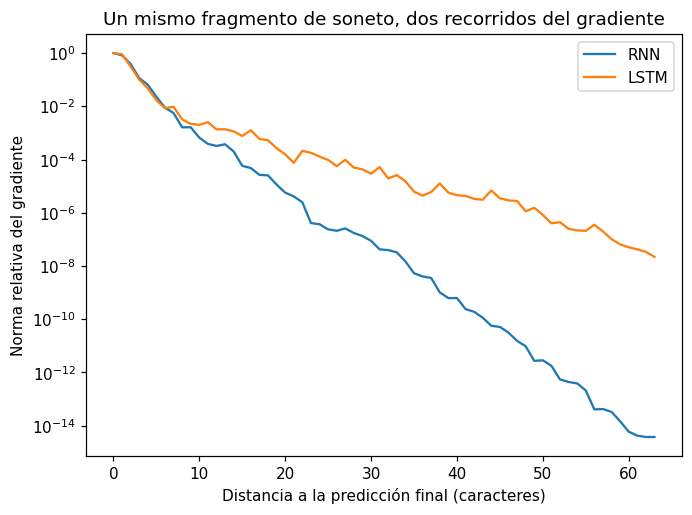

In [13]:
def sensibilidad(corpus, arq, inicio=0, pasos=64):
    red = modelos[corpus, arq]
    frag = datos[corpus]["val"][0][inicio:inicio + pasos + 1].to(DISP)
    emb = red.embedding(frag[:-1][None]).detach().requires_grad_()
    # La implementación nativa permite diferenciar en modo evaluación también en GPU.
    with torch.backends.cudnn.flags(enabled=False):
        estados, _ = red.recurrente(emb)
        perdida = nn.functional.cross_entropy(red.salida(estados[:, -1]), frag[-1:])
        grad, = torch.autograd.grad(perdida, emb)
    normas = grad[0].norm(dim=1).flip(0).cpu()
    return normas / normas[0].clamp_min(1e-30)

for arq in ("RNN", "LSTM"):
    plt.semilogy(sensibilidad("Sonetos", arq).clamp_min(1e-30), label=arq)
plt.xlabel("Distancia a la predicción final (caracteres)")
plt.ylabel("Norma relativa del gradiente")
plt.title("Un mismo fragmento de soneto, dos recorridos del gradiente")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Código Python · completa el cuerpo de una función
Una firma, dos puntos y un salto de línea ya ofrecen pistas sobre la indentación. Después de `return ` aparece otra dificultad. Hay muchas expresiones legales y solo algunas cumplen la intención del programador.

Entrenamos **dos modelos nuevos** sobre código fuente real. En el primer ejemplo, observa si completan un identificador, cierran los delimitadores y usan el argumento de la función. Revisa cada criterio por separado.

Python · RNN entrenada · CE final 2.060
Python · LSTM entrenada · CE final 1.974
Unigrama · CE 3.249 · PPL 25.77


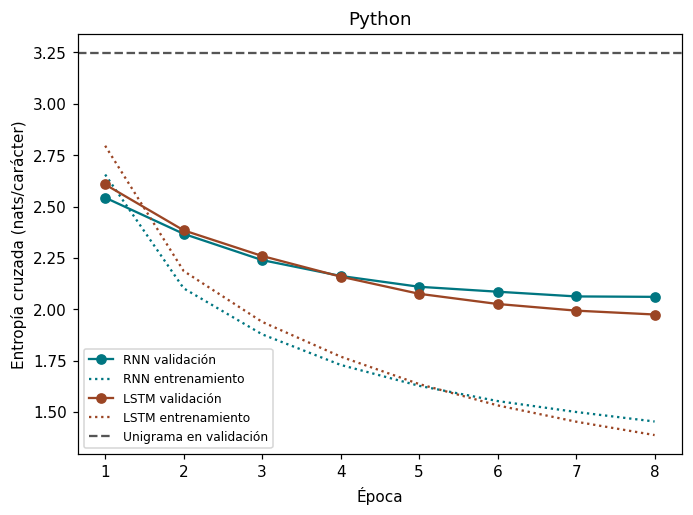

,CE_val,PPL_val,parámetros,segundos
modelo,,,,
RNN,2.060,7.847,25122,4.912
LSTM,1.974,7.201,62562,4.438


In [14]:
entrenar_par("Python")
comparar("Python")

In [15]:
firma = "def doble(x):\n    return "
chat("Python", firma, longitud=100, temperatura=0.7, top_k=5)

### Ejemplo resuelto · de «parece Python» a una comprobación
La especificación pide devolver el doble del argumento. Una solución de referencia es `return 2 * x`. Para evaluar las predicciones aislamos la **primera línea** que sigue a `return ` y la insertamos en la función. La métrica acepta una función con un único `return` que contiene una expresión. Una expresión desconocida como `total` puede pasar ese filtro y fallar cuando se llama a la función.

Ejecuta la solución escrita a mano con tres entradas. Luego observa cuántas de diez continuaciones de cada red pasan el filtro sintáctico. Las muestras generadas solo se analizan con `ast.parse`.

In [16]:
def doble(x):
    return 2 * x

for entrada, esperado in [(0, 0), (3, 6), (-2, -4)]:
    assert doble(entrada) == esperado
    print(f"doble({entrada}) = {esperado}")

def retorno_con_expresion(linea):
    try:
        cuerpo = ast.parse(firma + linea + "\n").body[0].body
    except (SyntaxError, ValueError):
        return False
    return len(cuerpo) == 1 and isinstance(cuerpo[0], ast.Return) and cuerpo[0].value is not None

assert retorno_con_expresion("2 * x")
assert not retorno_con_expresion("(")
assert not retorno_con_expresion("")

doble(0) = 0
doble(3) = 6
doble(-2) = -4


In [17]:
resultados = []
for arq in ("RNN", "LSTM"):
    for semilla in range(10):
        texto, _ = continuar("Python", arq, firma, longitud=96,
                             temperatura=0.7, top_k=5, semilla=semilla)
        linea, salto, _ = texto.partition("\n")
        # Si se agotan los 96 caracteres, clasificamos como línea inconclusa.
        resultados.append(dict(modelo=arq, semilla=semilla, propuesta=linea,
                               cerró_línea=bool(salto),
                               retorno_analizable=bool(salto) and retorno_con_expresion(linea)))
muestras = pd.DataFrame(resultados)
display(muestras[muestras.semilla < 3].set_index(["modelo", "semilla"]))
display(muestras.groupby("modelo").agg(intentos=("semilla", "size"),
                                      líneas_completas=("cerró_línea", "sum"),
                                      retornos_analizables=("retorno_analizable", "sum")))

propuesta  ...  retorno_analizable
modelo semilla                                                     ...                    
RNN    0        line = firgen whitespace('__str_nstance words ...  ...               False
       1           widthenteds in whitedented wrapper(fauld_type)  ...               False
       2        wint width wod chunks in line) = return of tha...  ...               False
LSTM   0                                   the text = self.width'  ...               False
       1                                            willitespace.  ...               False
       2                                            will widt the  ...               False

[6 rows x 3 columns]

,intentos,líneas_completas,retornos_analizables
modelo,,,
LSTM,10,7,1
RNN,10,8,1


**Inspecciona los aciertos del filtro.** Imagina que llamas a la función en un archivo que solo contiene su definición. ¿De dónde saldría cada nombre que aparece en la expresión? Busca al menos una razón por la que una línea admitida por el analizador puede producir un error o devolver el valor equivocado.

In [18]:
aceptadas = muestras[muestras.retorno_analizable]
if aceptadas.empty:
    print("Ninguna propuesta pasó el filtro en esta corrida.")
for fila in aceptadas.itertuples():
    print(f"{fila.modelo}, semilla {fila.semilla}: return {fila.propuesta}")

RNN, semilla 6: return width
LSTM, semilla 6: return width(self, bot)


## 6. Lee los resultados

La tabla reúne los resultados finales de la ejecución. **CE ganada al unigrama** es la resta CE del unigrama menos CE de la red. Un valor positivo indica que la red mejoró sobre las frecuencias de letras. Para juzgar el código, contrasta la puntuación con las líneas generadas en la sección 5.

In [19]:
filas = []
for corpus, df in historial.items():
    for _, r in df[df["época"] == EPOCAS].iterrows():
        filas.append({"Corpus": corpus, "Red": r.modelo, "CE de validación": r.CE_val,
                      "CE ganada al unigrama": ce_unigrama(datos[corpus]) - r.CE_val,
                      "Parámetros": r.parámetros, "Segundos de entrenamiento y validación": r.segundos})
display(pd.DataFrame(filas).set_index(["Corpus", "Red"]).round(3))

CE de validación  ...  Segundos de entrenamiento y validación
Corpus  Red                     ...                                        
Sonetos RNN              1.815  ...                                   4.006
        LSTM             1.808  ...                                   3.889
Python  RNN              2.060  ...                                   4.912
        LSTM             1.974  ...                                   4.438

[4 rows x 4 columns]

**Lectura de la ejecución de referencia (CPU, semilla 42).** En sonetos, la perplejidad pasó de 6.14 con la RNN a 6.10 con la LSTM. En Python la diferencia fue mayor, de 7.85 a 7.20. Sin embargo, solo una de las diez propuestas de cada red pasó el filtro. La RNN escribió `return width` y la LSTM escribió `return width(self, bot)`. Ambas líneas son Python válido. Dentro de la función del ejercicio, `width` carece de definición y ninguna propuesta utiliza el argumento `x`. La pérdida mide la calidad de las predicciones de caracteres. La prueba de la función responde otra pregunta: ¿devuelve el doble del argumento?

Si vuelves a entrenar con otra versión de Python, otro dispositivo o más épocas, contrasta tu corrida con estos resultados.

## 7. Chat de continuaciones
Elige **Sonetos** o **Python**, escribe un prefijo y pulsa **Generar**. Con **Ambos**, cada red recibe exactamente el mismo texto y la misma semilla. Cada turno empieza con el prefijo visible. Estos modelos aprendieron a continuar texto carácter por carácter, así que puedes probar `Shall I `, `class ` o una función con saltos de línea.

¿Quieres comparar temperaturas? Mantén el prefijo y la semilla, cambia solo la temperatura y vuelve a generar. Los turnos se acumulan para que puedas comparar. **Limpiar** borra el historial visible. Si tu entorno no muestra controles, usa la llamada editable que sigue.

In [20]:
def abrir_chat():
    import ipywidgets as w
    corpus = w.Dropdown(options=list(datos), description="Corpus")
    modelo = w.Dropdown(options=["Ambos", "RNN", "LSTM"], description="Modelo")
    prefijo = w.Textarea(value="Shall I ", description="Prefijo", rows=3,
                        layout=w.Layout(width="95%"))
    temperatura = w.FloatSlider(value=0.8, min=0.2, max=1.6, step=0.1, description="Temp.")
    k = w.IntSlider(value=8, min=1, max=30, description="Top-k")
    longitud = w.IntSlider(value=140, min=20, max=400, step=20, description="Caracteres")
    semilla = w.BoundedIntText(value=7, min=0, max=99999, description="Semilla")
    enviar = w.Button(description="Generar", button_style="primary")
    limpiar = w.Button(description="Limpiar")
    salida = w.Output()
    def cambiar_corpus(evento):
        prefijo.value = "Shall I " if evento["new"] == "Sonetos" else firma
    def generar(_):
        with salida:
            try:
                print(f"{corpus.value} · T={temperatura.value:g} · k={k.value} · semilla {semilla.value}")
                chat(corpus.value, prefijo.value, longitud.value, temperatura.value,
                     k.value, semilla.value, modelo.value)
            except ValueError as error:
                print(error)
    corpus.observe(cambiar_corpus, names="value")
    enviar.on_click(generar)
    limpiar.on_click(lambda _: salida.clear_output())
    display(w.VBox([w.HBox([corpus, modelo]), prefijo, w.HBox([temperatura, k]),
                    w.HBox([longitud, semilla]), w.HBox([enviar, limpiar]), salida]))

try:
    abrir_chat()
except ImportError:
    print("Usa la celda siguiente para conversar sin widgets.")

Ejecuta esta celda para abrir los controles del chat.


In [21]:
# Alternativa sin widgets. Edita y vuelve a ejecutar únicamente esta celda.
chat(corpus="Python", prefijo="class ", modelo="Ambos",
     longitud=100, temperatura=0.8, top_k=8, semilla=7)

### Cierre · defiende una elección
1. **Como lector.** Prueba `Shall I ` con `top_k=1` y dos semillas. Predice qué cambiará y compruébalo. Después repite con `top_k=8`. ¿En qué paso empiezan a diferir las muestras?
2. **Como programador.** Elige una expresión generada que pase el filtro. ¿Qué devolvería para `x=-2`? Explica qué evidencia falta para afirmar que cumple el contrato. Si ninguna pasa, identifica el primer error de una muestra.
3. **Como responsable del modelo.** Elige una red para una demo de autocompletado. Sustenta tu elección con su pérdida, su costo y una muestra. Para sostener una conclusión más general, ¿qué cambiarías primero en el experimento: semillas de entrenamiento, presupuesto de parámetros o corpus?

**Para profundizar** · [Sonetos utilizados](https://github.com/ccc-frankfurt/Practical_ML_SS21/blob/master/week06/sonnets.txt) · [Código fuente de CPython](https://github.com/python/cpython/tree/main/Lib) · [RNN en PyTorch](https://pytorch.org/docs/stable/generated/torch.nn.RNN.html) · [LSTM en PyTorch](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html) · [Hochreiter y Schmidhuber, 1997](https://doi.org/10.1162/neco.1997.9.8.1735).